# Femoco paper figures: |i⟩ distillation via a triangular code

Figures and tables for the part "Clifford resource state preparation" and appendix "|i⟩-state distillation" of the Femoco paper, *Ground-state energy estimation
compiled on cat qubits: 7 164 qubits for FeMoco-54 in 23.5 hours* ([arXiv:2610.37840](https://arxiv.org/abs/2610.37840)):

1. `femoco_slope`: $p_z^{d_c}$ slopes for the logical error rates at $d_c = 3, 5, 7$ when the numbers $k$ of repetition-code preparatory cycles are high enough.
2. `femoco_ler_vs_pz_short`, `_medium`, `_long`: $p_z$ dependence of logical error rates at fixed durations, i.e. $k = 1, 4, 8$.
3. `femoco_ler_vs_dr`: repetition-code distance $d_r$ dependence of the logical error rate at $p_z = 2.5\times10^{-3}$. The
   regime changes as expected around $d_r = 2 d_c - 1$.
4. `femoco_ler_vs_n_prep`: $k$ dependence of the logical error rate at $d_c = 5 \text{ and } 7$, one
   curve per $p_z$.
5. `femoco_acceptance_vs_n_prep`: $k$ independence of the acceptance 
6. `femoco_acceptance_vs_pz`: $p_z$ dependence of the acceptance at fixed $d_c$.
7. `femoco_acceptance_tau_table.tex`: table showing that Figure 6's $\tau$ is proportional to the number of colour-code
   data qubits.
8. `femoco_istate_*.tex`: tables used in the paper, i.e. the qubit counts and Crumble circuits, the protocol types, and the logical error rates at $p_z = 10^{-3} \text{ and } 5\times10^{-4}$.

- Each point is the estimate failures / accepted, with a **two-sided 95% Poisson interval**. A point with no
  failure is drawn as its one-sided 95% upper bound, with a downward arrow.

Outputs, in this folder: each figure as `.pdf`, each table as `.tex`.

Inputs: the results folders under `output/Results` and the circuits in `circuits/`. Run it from an environment where
`distillation_simu` is importable, e.g. after `pip install -e .` at the repository root.

In [1]:
import math
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

from distillation_simu.common.statistics import fit_power_law, poisson_lower_limit, poisson_upper_limit
from distillation_simu.paths import OUTPUT_DIR, REPO_ROOT
from distillation_simu.simu_lab.result_counts import load_counts

RESULTS = OUTPUT_DIR / "Results"
FIGURES = OUTPUT_DIR / "figures"
CONFIDENCE = 0.95

Precisions about the parameter $k$, the number of repetition-code preparatory cycles `rep_prep_cycles`: It is the number of repetition-code cycles finished or started when the first physical CNOT of the logical CNOT is performed, so $k \geq 1$. The coupling shares its timestep with the reset that starts cycle $k + 1$, which does not count. A protocol takes $k + 1$ repetition-code cycles. Data, figures and tables all use $k$.

In [2]:
PROTOCOLS = {"short": 1, "medium": 4, "long": 8}  # name -> k


def prep_label(k: int) -> str:
    return f"$k={k}$"

## Preliminaries
### Result folders

Each result folder under `output/Results` corresponds to an experiment sweeping over a specified set of parameters, as described by
- `simulation_manifest.json` (what was simulated, and how the result paths encode it)
- `simulation_manifest.lock` (per point, a fingerprint of the simulated detector error model, and the package versions)
- `results.pack.json` (actual results, compressed into one large file).


Parameters used throughout: `cnot_dense_two_step_symmetric` (choice of CNOT scheduling in the $Z$ stabiliser circuits), `dstl_Zflag_selec=True` (the Bell flags are measured and selected on), tesseract.

Points are pooled by $(d_c, d_r, k, p_z)$, across jobs and folders. A folder with no results is skipped, with a notice.

In [3]:
FOLDERS = [
    "261008 - rep prep cycles d_color 3",
    "261024 - rep code distance",
    "260924 - dense with symmetric schedule/high pz",
    "260924 - dense with symmetric schedule/low pz",
    "261002 - rep prep cycles d_color 5/high pz",
    "261002 - rep prep cycles d_color 5/pz 5e-4",
    "261002 - rep prep cycles d_color 5/high pz k 5-6",
    "261002 - rep prep cycles d_color 5/high pz k 7",
    "261023 - rep bell pairs d_color 5",
    "260929 - dense with symmetric schedule d_color 7",
    "261002 - rep prep cycles d_color 7/high pz",
    "261002 - rep prep cycles d_color 7/high pz k 7-8",
    "261002 - rep prep cycles d_color 7/high pz k 10",
    "261002 - rep prep cycles d_color 7/pz 2.5e-3 k 8",
    "261002 - rep prep cycles d_color 7/pz 2.5e-3 k 8 part 2",
    "261002 - rep prep cycles d_color 7/pz 5e-4",
    "261002 - rep prep cycles d_color 7/pz 1e-3",
    "260930 - dense with symmetric schedule d_color 9",
    "261012 - rep prep cycles d_color 9/high pz",
]
SHAPE = "cnot_dense_two_step_symmetric"

pooled = defaultdict(lambda: [0, 0, 0])  # (d_color, d, k, pz) -> [failures, accepted, attempted]
for folder in FOLDERS:
    if not (RESULTS / folder / "simulation_manifest.json").exists():
        print(f"skipped, no results yet: {folder}")
        continue
    for key, (nb_fail, nb_accepted, nb_shots) in load_counts(RESULTS / folder).items():
        point = dict(key)  # the point's parameters, as its folder's manifest and result paths record them
        assert point["mode"] == SHAPE, (folder, point)
        if point["rep_bell_pair_stabs"] != "none":
            continue  # 261023's paired configurations: a different circuit
        if nb_accepted == 0:
            continue  # no accepted shot: no rate to estimate
        entry = pooled[(point["d_color"], point["d"], point["rep_prep_cycles"] or 1, point["pz"])]
        entry[0] += nb_fail
        entry[1] += nb_accepted
        entry[2] += nb_shots

### Summary statistics of all results

Basic statistical analysis of every loaded result folder (estimates and confidence intervals).
Every statistical hypothesis we use is set out in
[`statistical_hypotheses.md`](statistical_hypotheses.md).

In [4]:
def row(d_color: int, d: int, k: int, pz: float, nb_fail: int, nb_accepted: int, nb_shots: int) -> dict:
    acceptance = nb_accepted / nb_shots
    zero_failure_bound = -math.expm1(math.log1p(-CONFIDENCE) / nb_accepted)
    r = {"d_color": d_color, "d": d, "k": k, "pz": pz, "failures": nb_fail,
         "accepted": nb_accepted, "shots": nb_shots, "acceptance": acceptance,
         # binomial, at 95% two-sided; shot counts are 1e6 or more, so the normal approximation holds
         "acceptance_err": 1.96 * math.sqrt(acceptance * (1 - acceptance) / nb_shots),
         # the one-sided 95% upper bound (exact binomial at n = 0, Poisson above); below "upper" when n >= 1,
         # which is the two-sided interval's 97.5% edge
         "upper_one_sided": zero_failure_bound if nb_fail == 0
                            else poisson_upper_limit(nb_fail, CONFIDENCE) / nb_accepted}
    if nb_fail == 0:
        r.update(estimate=None, upper=zero_failure_bound, lower=None)
    else:
        tail = 1 - (1 - CONFIDENCE) / 2
        r.update(estimate=nb_fail / nb_accepted, upper=poisson_upper_limit(nb_fail, tail) / nb_accepted,
                 lower=poisson_lower_limit(nb_fail, tail) / nb_accepted)
    return r


rows = sorted((row(*key, *counts) for key, counts in pooled.items()),
              key=lambda r: (r["d_color"], r["d"], r["k"], r["pz"]))


def select(**fixed) -> list:
    return [r for r in rows if all(math.isclose(r[name], value) for name, value in fixed.items())]


def print_table(title: str, table: list) -> None:
    print(title)
    print(f"{'d_c':>3} {'d_r':>3} {'k':>2} {'pz':>7} {'fails':>6} {'accepted':>10} {'estimate':>9} "
          f"{'95% interval':>21} {'95% bound':>9}")
    for r in table:
        est = "0" if r["estimate"] is None else f"{r['estimate']:.2e}"
        interval = f"< {r['upper']:.2e}" if r["lower"] is None else f"[{r['lower']:.2e}, {r['upper']:.2e}]"
        print(f"{r['d_color']:>3} {r['d']:>3} {r['k']:>2} {r['pz']:>7g} {r['failures']:>6} "
              f"{r['accepted']:>10.3g} {est:>9} {interval:>21} {r['upper_one_sided']:>9.2e}")
    print()

### Style

One colour and one marker per $d_c$ in every figure

In [5]:
plt.rcParams.update({
    "font.size": 9, "font.family": "DejaVu Sans", "axes.edgecolor": "0.35", "axes.linewidth": 0.6,
    "xtick.color": "0.25", "ytick.color": "0.25", "axes.labelcolor": "0.1", "legend.frameon": False,
    "savefig.bbox": "tight", "pdf.fonttype": 42,
})
COLOUR = {3: "#2a78d6", 5: "#eb6834", 7: "#1baf7a", 9: "#eda100"}
MARKER = {3: "o", 5: "s", 7: "^", 9: "D"}
D_R = {3: 9, 5: 13, 7: 19, 9: 19}  # the repetition-code distance each d_c is run at, outside the d_r scan
FIGSIZE = (4.7, 3.5)
PZ_TICKS = [5e-4, 1e-3, 2.5e-3, 5e-3, 1e-2]


# Each d_c's points are shifted sideways by a few percent on the pz axes, so that intervals and bounds of
# different d_c at the same pz do not sit on top of each other. The tables print the true pz.
DODGE = {3: 0.94, 5: 0.98, 7: 1.02, 9: 1.06}


def draw(ax, pts: list, x: str, d_color: int, label: str, dodge: bool = False, colour: str | None = None,
         marker: str | None = None) -> None:
    # Measured points: estimate + 95% interval, joined by a line. Zero-failure points: the bound, an arrow down,
    # joined to the series by a dashed line.
    colour, marker = colour or COLOUR[d_color], marker or MARKER[d_color]
    shift = DODGE[d_color] if dodge else 1.0
    measured = [r for r in pts if r["estimate"] is not None]
    xs = np.array([r[x] * shift for r in measured])
    ys = np.array([r["estimate"] for r in measured])
    yerr = np.array([[r["estimate"] - r["lower"] for r in measured], [r["upper"] - r["estimate"] for r in measured]])
    ax.errorbar(xs, ys, yerr=yerr, color=colour, marker=marker, markersize=5.5, markeredgecolor="white",
                markeredgewidth=0.8, linewidth=1.5, elinewidth=1.0, capsize=2, label=label, zorder=3)
    for r in pts:
        if r["estimate"] is not None:
            continue
        xb = r[x] * shift
        # pz is on a log axis; d and k are linear
        nearest = min(measured, key=lambda m: abs(math.log(m[x] / r[x])) if x == "pz" else abs(m[x] - r[x]))
        ax.plot([nearest[x] * shift, xb], [nearest["estimate"], r["upper"]], color=colour, linestyle="--",
                linewidth=1.0, zorder=2)
        ax.plot(xb, r["upper"], marker=marker, markersize=5.5, markerfacecolor="white", markeredgecolor=colour,
                markeredgewidth=1.2, linestyle="none", zorder=3)
        ax.annotate("", xy=(xb, r["upper"] / 12), xytext=(xb, r["upper"]),
                    arrowprops=dict(arrowstyle="-|>", color=colour, lw=1.0, shrinkA=3, shrinkB=0))


def pz_axis(ax) -> None:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("physical phase-flip probability $p_z$")
    ax.set_ylabel("logical error rate")
    ax.set_xticks(PZ_TICKS)
    ax.set_xticklabels([f"{t:g}" for t in PZ_TICKS])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.grid(True, which="major", color="0.9", lw=0.5)
    ax.set_xlim(4e-4, 1.25e-2)


def save(fig, name: str) -> None:
    fold = FIGURES / "femoco_paper"
    for ext in ("pdf",):
        fig.savefig(fold / f"{name}.{ext}", dpi=220)
    print("wrote", (fold / f"{name}.pdf").relative_to(REPO_ROOT))

## Figures

### Figure 1: reaching $d_c$ slopes for logical error rates

$d_c = 3, 5, 7$ at $k = 2, 4, 8$ repetition-code preparatory cycles. 

Each series gets a least-squares power law
through its measured points, with the fitted law, prefactor and exponent, in the
legend below the axes. 

A dotted guide of slope exactly $d_c$ is
anchored at the series' lowest-$p_z$ measured point.

d_c=3, k=2
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  3   9  2  0.0005    779   9.76e+09  7.98e-08  [7.43e-08, 8.56e-08]  8.47e-08
  3   9  2   0.001    897   1.43e+09  6.28e-07  [5.87e-07, 6.70e-07]  6.63e-07
  3   9  2  0.0025   1360   1.33e+08  1.02e-05  [9.70e-06, 1.08e-05]  1.07e-05
  3   9  2   0.005   2695   3.13e+07  8.60e-05  [8.28e-05, 8.93e-05]  8.88e-05
  3   9  2    0.01   4642   6.13e+06  7.57e-04  [7.36e-04, 7.79e-04]  7.76e-04

  fit: 946 * pz**3.06 +- 0.02   [segments: 5.0e-04->1.0e-03: 2.98, 1.0e-03->2.5e-03: 3.05, 2.5e-03->5.0e-03: 3.07, 5.0e-03->1.0e-02: 3.14] 

d_c=5, k=4
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  5  13  4  0.0005      5      3e+12  1.67e-12  [5.42e-13, 3.89e-12]  3.51e-12
  5  13  4   0.001      2   8.78e+10  2.28e-11  [2.76e-12, 8.23e-11]  7.17e-11
  5  13  4  0.0025    150   2.74e+10  5.47e-09  [4.63e-09, 6.42e-09]  6.27e-09
  5  13  4   0.005    286    1.2e+09  2.39e-07

wrote output/figures/femoco_paper/femoco_slope.pdf


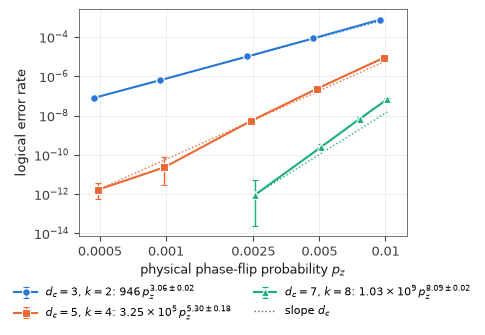

In [6]:
SLOPE_SERIES = {3: 2, 5: 4, 7: 8}  # d_c -> k
SLOPE_FITS = {}  # d_c -> the fit drawn in the legend; the tables below must extrapolate from these very fits


def latex_prefactor(a: float) -> str:
    # 946 stays 946; 3.25e5 becomes 3.25 \times 10^{5}
    exponent = math.floor(math.log10(a))
    return f"{a:.3g}" if exponent < 3 else f"{a / 10 ** exponent:.2f} \\times 10^{{{exponent}}}"


fig, ax = plt.subplots(figsize=FIGSIZE)
for d_color, k in SLOPE_SERIES.items():
    pts = select(d_color=d_color, d=D_R[d_color], k=k)
    print_table(f"d_c={d_color}, k={k}", pts)
    measured = [r for r in pts if r["estimate"] is not None]
    fit = fit_power_law([r["pz"] for r in measured], [r["estimate"] for r in measured])
    print("  fit:", fit, "\n")
    SLOPE_FITS[d_color] = fit
    err = "" if fit.exponent_stderr is None else f" \\pm {fit.exponent_stderr:.2f}"
    draw(ax, pts, "pz", d_color, f"$d_c={d_color}$, {prep_label(k)}: "
         f"${latex_prefactor(fit.prefactor)}\\, p_z^{{{fit.exponent:.2f}{err}}}$",
         dodge=True)
    lo = min(measured, key=lambda r: r["pz"])
    x_guide = np.array([lo["pz"], max(r["pz"] for r in measured)])
    ax.plot(x_guide * DODGE[d_color], lo["estimate"] * (x_guide / lo["pz"]) ** d_color, color=COLOUR[d_color], linestyle=":",
            linewidth=1.0, zorder=2)
ax.plot([], [], color="0.4", linestyle=":", linewidth=1.0, label="slope $d_c$")
pz_axis(ax)
# matplotlib lists plain lines before errorbar containers; put the guide back after the series
handles, labels = ax.get_legend_handles_labels()
handles, labels = handles[1:] + handles[:1], labels[1:] + labels[:1]
ax.legend(handles, labels, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
fig.tight_layout()
save(fig, "femoco_slope")
plt.show()

### Figures 2–4: protocols' logical error rates at fixed length

Short, medium and long: $k = 1, 4 \text{ and } 8$ repetition-code preparatory cycles, every $d_c$ simulated at that $k$, each at its
usual $d_r$. The three figures share their axes so they can be compared directly.

Each point shows the estimate with its two-sided 95% interval, as everywhere else, and also its **one-sided 95%
upper bound** (dotted, a tick per point). With $N_f \geq 1$ failures the bound sits
just under the interval's top edge, which is the 97.5% quantile; with $N_f = 0$ it is the drawn bound itself.

`DROPPED` leaves out $d_c = 7$ at $p_z = 5\times10^{-4}$ in the medium figure: 0 failures in 3.2e12 accepted shots, i.e. a bound
set by the shot count, not a measurement.

short: d_c=3, k=1
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  3   9  1  0.0005   1105   9.76e+09  1.13e-07  [1.07e-07, 1.20e-07]  1.19e-07
  3   9  1   0.001   1202   1.43e+09  8.41e-07  [7.94e-07, 8.90e-07]  8.82e-07
  3   9  1  0.0025   1830   1.33e+08  1.38e-05  [1.32e-05, 1.44e-05]  1.43e-05
  3   9  1   0.005   3482   3.13e+07  1.11e-04  [1.08e-04, 1.15e-04]  1.14e-04
  3   9  1    0.01   5434   6.12e+06  8.88e-04  [8.65e-04, 9.12e-04]  9.08e-04

short: d_c=5, k=1
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  5  13  1  0.0005     21   9.37e+10  2.24e-10  [1.39e-10, 3.43e-10]  3.23e-10
  5  13  1   0.001      9   4.39e+09  2.05e-09  [9.38e-10, 3.89e-09]  3.58e-09
  5  13  1  0.0025    279   2.52e+09  1.11e-07  [9.80e-08, 1.24e-07]  1.22e-07
  5  13  1   0.005    205   1.04e+08  1.97e-06  [1.71e-06, 2.26e-06]  2.21e-06
  5  13  1    0.01    149   5.39e+06  2.76e-05  [2.34e-05, 3.25e-05]  3.17e-05

short: d_c=7, 

wrote output/figures/femoco_paper/femoco_ler_vs_pz_short.pdf


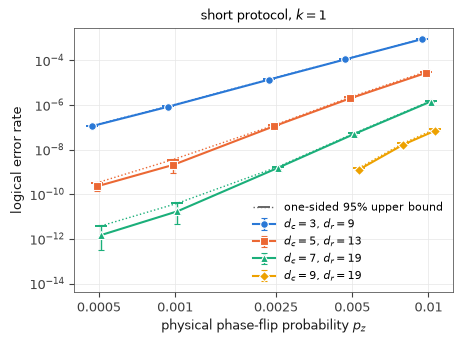

medium: d_c=5, k=4
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  5  13  4  0.0005      5      3e+12  1.67e-12  [5.42e-13, 3.89e-12]  3.51e-12
  5  13  4   0.001      2   8.78e+10  2.28e-11  [2.76e-12, 8.23e-11]  7.17e-11
  5  13  4  0.0025    150   2.74e+10  5.47e-09  [4.63e-09, 6.42e-09]  6.27e-09
  5  13  4   0.005    286    1.2e+09  2.39e-07  [2.12e-07, 2.68e-07]  2.64e-07
  5  13  4    0.01    330   3.79e+07  8.71e-06  [7.80e-06, 9.70e-06]  9.54e-06

medium: d_c=7, k=4
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  7  19  4  0.0005      0   3.18e+12         0            < 9.43e-13  9.43e-13
  7  19  4   0.001      1   1.56e+12  6.42e-13  [1.63e-14, 3.58e-12]  3.05e-12
  7  19  4   0.005     65   8.57e+09  7.58e-09  [5.85e-09, 9.67e-09]  9.32e-09
  7  19  4  0.0075    111   1.44e+09  7.73e-08  [6.36e-08, 9.31e-08]  9.05e-08
  7  19  4    0.01    114   2.04e+08  5.58e-07  [4.60e-07, 6.70e-07]  6.52e-07

medium: d_c=

wrote output/figures/femoco_paper/femoco_ler_vs_pz_medium.pdf


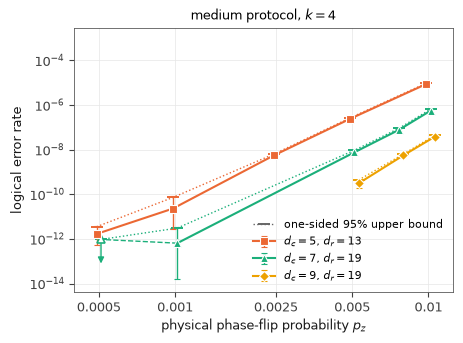

long: d_c=7, k=8
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  7  19  8  0.0025      1   1.07e+12  9.35e-13  [2.37e-14, 5.21e-12]  4.43e-12
  7  19  8   0.005     29   1.14e+11  2.54e-10  [1.70e-10, 3.64e-10]  3.46e-10
  7  19  8  0.0075     67   9.63e+09  6.96e-09  [5.39e-09, 8.84e-09]  8.53e-09
  7  19  8    0.01    100   1.47e+09  6.80e-08  [5.53e-08, 8.27e-08]  8.02e-08



wrote output/figures/femoco_paper/femoco_ler_vs_pz_long.pdf


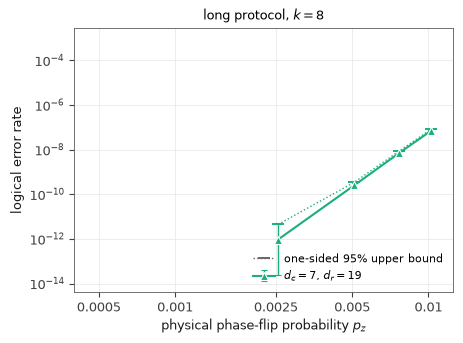

In [7]:
FIXED_LENGTH_D_COLORS = {"short": (3, 5, 7, 9), "medium": (5, 7, 9), "long": (7,)}
# (protocol, d_c) -> pz left out of the figure, though still in the tables elsewhere: a zero-failure bound set by
# the shot count rather than the rate, which says nothing the 1e-3 point above it does not.
DROPPED = dict() #{("medium", 7): {5e-4}}


def fixed_length_points(name: str, k: int, d_color: int) -> list:
    dropped = DROPPED.get((name, d_color), set())
    return [r for r in select(d_color=d_color, d=D_R[d_color], k=k)
            if not any(math.isclose(r["pz"], pz) for pz in dropped)]


def draw_upper_bound(ax, pts: list, d_color: int) -> None:
    # The one-sided 95% upper bound of every point, beside the estimate and its two-sided interval: a thin dotted
    # line in the series' colour, a horizontal tick at each bound. Same sideways shift as draw(..., dodge=True).
    xs = [r["pz"] * DODGE[d_color] for r in pts]
    ax.plot(xs, [r["upper_one_sided"] for r in pts], color=COLOUR[d_color], linestyle=":", linewidth=1.0,
            marker="_", markersize=9, markeredgewidth=1.4, zorder=2)


measured_bounds = [r for name, k in PROTOCOLS.items() for d_color in FIXED_LENGTH_D_COLORS[name]
                   for r in fixed_length_points(name, k, d_color)]
Y_LIM = (min(r["lower"] or r["upper"] for r in measured_bounds) / 4, max(r["upper"] for r in measured_bounds) * 3)

for name, k in PROTOCOLS.items():
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for d_color in FIXED_LENGTH_D_COLORS[name]:
        pts = fixed_length_points(name, k, d_color)
        print_table(f"{name}: d_c={d_color}, k={k}", pts)
        draw(ax, pts, "pz", d_color, f"$d_c={d_color}$, $d_r={D_R[d_color]}$", dodge=True)
        draw_upper_bound(ax, pts, d_color)
    ax.plot([], [], color="0.4", linestyle=":", linewidth=1.0, marker="_", markersize=9, markeredgewidth=1.4,
            label="one-sided 95% upper bound")
    pz_axis(ax)
    ax.set_ylim(*Y_LIM)
    ax.set_title(f"{name} protocol, {prep_label(k)}", fontsize=9)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    save(fig, f"femoco_ler_vs_pz_{name}")
    plt.show()

### Figure 5: influence of the repetition-code distance

$p_z = 2.5\times10^{-3}$, with $d_r \in \{2d_c-3, 2d_c-1, 2d_c+1, 2d_c+3\}$.

While the repetition code limits the logical error rate, its contribution is mitigated by error correction and is thus expected to fall as $p_z^{(d_r+1)/2}$, which is a straight line on this log-linear plot. 

Once that term drops below the colour code's $p_z^{d_c}$, which happens at $d_r = 2d_c - 1$ (dotted), the rate is expected to flatten, which is indeed observed.

d_c=3, k=2, pz=0.0025
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  3   3  2  0.0025  30408   1.32e+08  2.30e-04  [2.27e-04, 2.32e-04]  2.32e-04
  3   5  2  0.0025   2110   1.33e+08  1.59e-05  [1.52e-05, 1.66e-05]  1.65e-05
  3   7  2  0.0025   1364   1.33e+08  1.03e-05  [9.73e-06, 1.08e-05]  1.07e-05
  3   9  2  0.0025   1360   1.33e+08  1.02e-05  [9.70e-06, 1.08e-05]  1.07e-05

d_c=5, k=4, pz=0.0025
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  5   7  4  0.0025   1037   5.77e+09  1.80e-07  [1.69e-07, 1.91e-07]  1.89e-07
  5   9  4  0.0025    209   1.73e+10  1.21e-08  [1.05e-08, 1.38e-08]  1.35e-08
  5  11  4  0.0025    108   1.73e+10  6.24e-09  [5.12e-09, 7.53e-09]  7.32e-09
  5  13  4  0.0025    150   2.74e+10  5.47e-09  [4.63e-09, 6.42e-09]  6.27e-09



wrote output/figures/femoco_paper/femoco_ler_vs_dr.pdf


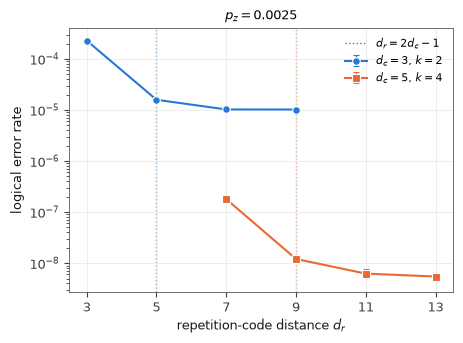

In [8]:
DR_PZ = 2.5e-3
DR_SERIES = {3: 2, 5: 4}  # d_c -> k

fig, ax = plt.subplots(figsize=FIGSIZE)
for d_color, k in DR_SERIES.items():
    pts = sorted((r for r in select(d_color=d_color, k=k, pz=DR_PZ) if r["d"] in range(2 * d_color - 3, 2 * d_color + 4)),
                 key=lambda r: r["d"])
    print_table(f"d_c={d_color}, k={k}, pz={DR_PZ:g}", pts)
    draw(ax, pts, "d", d_color, f"$d_c={d_color}$, {prep_label(k)}")
    ax.axvline(2 * d_color - 1, color=COLOUR[d_color], linestyle=":", linewidth=1.0, zorder=1)
ax.plot([], [], color="0.4", linestyle=":", linewidth=1.0, label="$d_r = 2d_c-1$")
ax.set_yscale("log")
ax.set_xticks(range(3, 14, 2))
ax.set_xlabel("repetition-code distance $d_r$")
ax.set_ylabel("logical error rate")
ax.set_title(f"$p_z = {DR_PZ:g}$", fontsize=9)
ax.grid(True, which="major", color="0.9", lw=0.5)
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
save(fig, "femoco_ler_vs_dr")
plt.show()

### Figure 4: influence of the number of repetition-code preparatory cycles

The logical error rate against $k$. One curve per $p_z$. The encoding is the same in both
panels of Figure 4, so one legend above them serves both.

d_c=5, pz=0.01
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  5  13  1    0.01    149   5.39e+06  2.76e-05  [2.34e-05, 3.25e-05]  3.17e-05
  5  13  2    0.01    404   1.62e+07  2.49e-05  [2.25e-05, 2.75e-05]  2.70e-05
  5  13  3    0.01    213   1.62e+07  1.31e-05  [1.14e-05, 1.50e-05]  1.47e-05
  5  13  4    0.01    330   3.79e+07  8.71e-06  [7.80e-06, 9.70e-06]  9.54e-06
  5  13  5    0.01    131   2.16e+07  6.05e-06  [5.06e-06, 7.18e-06]  7.00e-06
  5  13  6    0.01    228   4.33e+07  5.27e-06  [4.61e-06, 6.00e-06]  5.88e-06
  5  13  7    0.01    182   4.33e+07  4.20e-06  [3.62e-06, 4.86e-06]  4.75e-06

d_c=5, pz=0.005
d_c d_r  k      pz  fails   accepted  estimate          95% interval 95% bound
  5  13  1   0.005    205   1.04e+08  1.97e-06  [1.71e-06, 2.26e-06]  2.21e-06
  5  13  2   0.005    262   2.08e+08  1.26e-06  [1.11e-06, 1.42e-06]  1.39e-06
  5  13  3   0.005    187   4.16e+08  4.49e-07  [3.87e-07, 5.19e-07]  5.07e-07
  5  13  4   0.005  

wrote output/figures/femoco_paper/femoco_ler_vs_n_prep.pdf


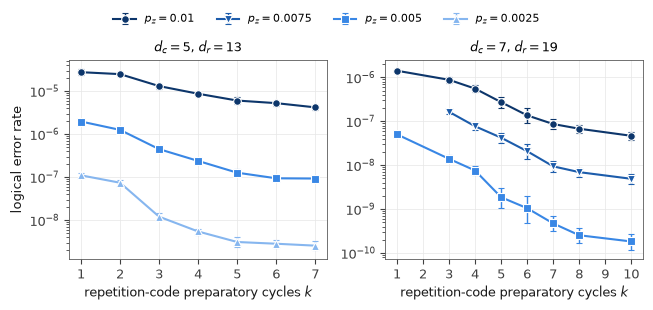

In [9]:
K_SCAN_D_COLORS = (5, 7)
PZ_COLOUR = {1e-2: "#0d366b", 7.5e-3: "#1c5cab", 5e-3: "#3987e5", 2.5e-3: "#86b6ef"}  # blue ramp, steps 700/550/400/250
PZ_MARKER = {1e-2: "o", 7.5e-3: "v", 5e-3: "s", 2.5e-3: "^"}
K_SCAN_SKIP = {(7, 2.5e-3)}  # (d_c, pz) left out: k = 1 and 8 only, a bare line across the panel

fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.1))
for ax, d_color in zip(axes, K_SCAN_D_COLORS):
    for pz in PZ_COLOUR:
        pts = sorted(select(d_color=d_color, d=D_R[d_color], pz=pz), key=lambda r: r["k"])
        if len(pts) < 2 or any(d_color == d and math.isclose(pz, p) for d, p in K_SCAN_SKIP):
            continue
        print_table(f"d_c={d_color}, pz={pz:g}", pts)
        draw(ax, pts, "k", d_color, f"$p_z={pz:g}$", colour=PZ_COLOUR[pz], marker=PZ_MARKER[pz])
    ax.set_yscale("log")
    ax.set_xlabel("repetition-code preparatory cycles $k$")
    ax.set_title(f"$d_c={d_color}$, $d_r={D_R[d_color]}$", fontsize=9)
    ax.xaxis.set_major_locator(plt.MultipleLocator(1))
    ax.grid(True, which="major", color="0.9", lw=0.5)
axes[0].set_ylabel("logical error rate")
# One legend over both panels: neither panel has every pz (2.5e-3 is d_c=5 only, 7.5e-3 d_c=7 only).
by_label = {}
for ax in axes:
    by_label.update(zip(*reversed(ax.get_legend_handles_labels())))
order = [f"$p_z={pz:g}$" for pz in PZ_COLOUR if f"$p_z={pz:g}$" in by_label]
fig.legend([by_label[label] for label in order], order, fontsize=8, loc="upper center", ncol=len(order),
           bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "femoco_ler_vs_n_prep")
plt.show()

### Figure 5: acceptance vs number of preparatory cycles

Printed small, beside Figure 6 (about 2 in wide), so it is drawn at that size rather than at `FIGSIZE`.

series shown (d_c, pz): [(3, 0.0005), (3, 0.001), (3, 0.0025), (5, 0.0005), (5, 0.001), (5, 0.0025), (7, 0.0005), (7, 0.001)]


wrote output/figures/femoco_paper/femoco_acceptance_vs_n_prep.pdf


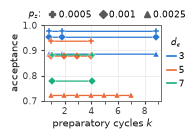

In [10]:
ACC_PZ_MARKER = {**PZ_MARKER, 1e-3: "D", 5e-4: "P"}
ACC_X_SHIFT = {3: -0.18, 5: -0.06, 7: 0.06, 9: 0.18}


def acceptance_legends(fig, d_colors=(3, 5, 7, 9), pzs=tuple(ACC_PZ_MARKER)) -> None:
    # Two rows above the axes: d_c (colour), then p_z (marker). Call before tight_layout, which leaves them room.
    d_handles = [plt.Line2D([], [], color=COLOUR[d], linewidth=1.5, label=f"$d_c={d}$") for d in d_colors]
    pz_handles = [plt.Line2D([], [], color="0.35", marker=ACC_PZ_MARKER[pz], linestyle="none", markersize=5,
                             label=f"$p_z={pz:g}$") for pz in ACC_PZ_MARKER if pz in pzs]
    fig.legend(handles=d_handles, fontsize=8, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0))
    fig.legend(handles=pz_handles, fontsize=7.5, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 0.935),
               handletextpad=0.2, columnspacing=0.9)


MIN_K, MAX_PZ = 4, 2.5e-3
ACC_SKIP = {(7, 2.5e-3)}  # (d_c, pz) left out whatever the two cuts say: at 0.53, it would double the y range

# Printed small: (b) of the acceptance figure is 0.37 * 0.85 of the 6.27in text width, about 2in, so the figure is
# drawn at that size, with fonts that land near panel (a)'s ~7pt once both are scaled into the page.
SMALL = {"font.size": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "xtick.major.size": 2.5,
         "ytick.major.size": 2.5, "xtick.major.pad": 2, "ytick.major.pad": 2, "axes.labelpad": 2}
with plt.rc_context(SMALL):
    fig, ax = plt.subplots(figsize=(2.0, 1.42))
    shown = set()
    for d_color in (3, 5, 7, 9):
        for pz, marker in ACC_PZ_MARKER.items():
            pts = sorted(select(d_color=d_color, d=D_R[d_color], pz=pz), key=lambda r: r["k"])
            skip = any(d_color == d and math.isclose(pz, p) for d, p in ACC_SKIP)
            if skip or len(pts) < 2 or max(r["k"] for r in pts) < MIN_K or pz > MAX_PZ * (1 + 1e-9):
                continue
            shown.add((d_color, pz))
            ax.errorbar(np.array([r["k"] for r in pts]) + ACC_X_SHIFT[d_color], [r["acceptance"] for r in pts],
                        yerr=[r["acceptance_err"] for r in pts], color=COLOUR[d_color], marker=marker, markersize=4,
                        markeredgecolor="white", markeredgewidth=0.3, linewidth=0.9, elinewidth=0.7, capsize=1,
                        zorder=3)
    ax.set_xlabel("preparatory cycles $k$")
    ax.set_ylabel("acceptance")
    ax.set_ylim(0.7, 1.0)
    ax.xaxis.set_major_locator(plt.MultipleLocator(2))
    ax.xaxis.set_minor_locator(plt.MultipleLocator(1))
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
    ax.grid(True, which="major", color="0.9", lw=0.5)
    # d_c by colour in a column on the right, top to bottom in the order the acceptance falls; p_z by marker in one
    # row centred over the axes, led by a handle-less "p_z:". Placed after tight_layout, which sizes the axes.
    fig.tight_layout(rect=(0, 0, 0.86, 0.91))
    d_colors, pzs = sorted({d for d, _ in shown}), sorted({pz for _, pz in shown})
    compact = dict(fontsize=6.5, handletextpad=0.3, borderaxespad=0, borderpad=0)
    box = ax.get_position()
    fig.legend(handles=[plt.Line2D([], [], linestyle="none", label="$p_z$:")]
                       + [plt.Line2D([], [], color="0.35", marker=ACC_PZ_MARKER[pz], linestyle="none", markersize=4,
                                     label=f"{pz:g}") for pz in pzs],
               loc="lower center", ncol=len(pzs) + 1, bbox_to_anchor=((box.x0 + box.x1) / 2, box.y1 + 0.04),
               handlelength=0.8, columnspacing=0.8, **compact)
    fig.legend(handles=[plt.Line2D([], [], color=COLOUR[d], linewidth=1.2, label=f"{d}") for d in d_colors],
               title="$d_c$", title_fontsize=6.5, loc="center left", bbox_to_anchor=(box.x1 + 0.03, (box.y0 + box.y1) / 2),
               handlelength=1.0, labelspacing=0.4, **compact)
    print("series shown (d_c, pz):", sorted(shown))
    save(fig, "femoco_acceptance_vs_n_prep")
    plt.show()

### Figure 6: acceptance against $p_z$

Only for the short protocol $k = 1$. Since the acceptance does not depend on $k$ (Figure 5, to ≤ 0.6%), this holds for every length. 

The dashed lines are one-parameter fits of `exp(−τ·p_z)` per $d_c$, least squares on log(acceptance), with $\tau$ in the legend. 
In the case of $d_c = 9$, the fit is extrapolated well below the measured values of $p_z$.

d_c=3: acceptance ~ exp(-49 pz); 0.0005: 0.9759 (fit 0.9758), 0.001: 0.9524 (fit 0.9521), 0.0025: 0.8851 (fit 0.8845), 0.005: 0.7830 (fit 0.7823), 0.01: 0.6117 (fit 0.6120)
d_c=5: acceptance ~ exp(-131 pz); 0.0005: 0.9367 (fit 0.9366), 0.001: 0.8775 (fit 0.8772), 0.0025: 0.7211 (fit 0.7206), 0.005: 0.5197 (fit 0.5193), 0.01: 0.2695 (fit 0.2697)
d_c=7: acceptance ~ exp(-251 pz); 0.0005: 0.8822 (fit 0.8821), 0.001: 0.7783 (fit 0.7781), 0.0025: 0.5343 (fit 0.5341), 0.005: 0.2854 (fit 0.2853), 0.01: 0.0814 (fit 0.0814)
d_c=9: acceptance ~ exp(-409 pz); 0.005: 0.1296 (fit 0.1297), 0.0075: 0.0467 (fit 0.0467), 0.01: 0.0168 (fit 0.0168)


wrote output/figures/femoco_paper/femoco_acceptance_vs_pz.pdf


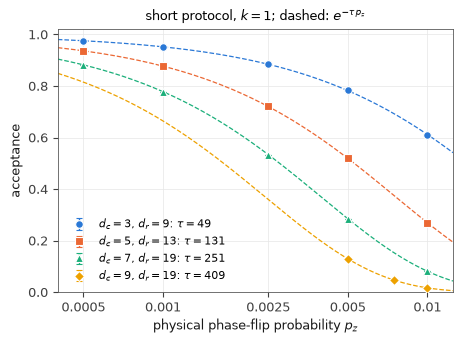

In [12]:
ACCEPTANCE_TAU = {}  # d_c -> tau, for the table below
fig, ax = plt.subplots(figsize=FIGSIZE)
for d_color in FIXED_LENGTH_D_COLORS["short"]:
    pts = select(d_color=d_color, d=D_R[d_color], k=PROTOCOLS["short"])
    pz = np.array([r["pz"] for r in pts])
    tau = -float(np.sum(pz * np.log([r["acceptance"] for r in pts])) / np.sum(pz ** 2))
    print(f"d_c={d_color}: acceptance ~ exp(-{tau:.0f} pz);",
          ", ".join(f"{r['pz']:g}: {r['acceptance']:.4f} (fit {math.exp(-tau * r['pz']):.4f})" for r in pts))
    ACCEPTANCE_TAU[d_color] = tau
    x_fit = np.geomspace(4e-4, 1.25e-2, 200)
    ax.plot(x_fit, np.exp(-tau * x_fit), color=COLOUR[d_color], linestyle="--", linewidth=0.9, zorder=2)
    ax.errorbar(pz, [r["acceptance"] for r in pts], yerr=[r["acceptance_err"] for r in pts],
                color=COLOUR[d_color], marker=MARKER[d_color], markersize=5.5, markeredgecolor="white",
                markeredgewidth=0.8, linestyle="none", elinewidth=1.0, capsize=2, zorder=3,
                label=f"$d_c={d_color}$, $d_r={D_R[d_color]}$: $\\tau={tau:.0f}$")
pz_axis(ax)
ax.set_ylabel("acceptance")
ax.set_yscale("linear")
ax.set_ylim(0, 1.02)
ax.set_title(f"short protocol, {prep_label(PROTOCOLS['short'])}; dashed: $e^{{-\\tau\\,p_z}}$", fontsize=9)
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
save(fig, "femoco_acceptance_vs_pz")
plt.show()

## Tables

### Table: $\tau$ is proportional to the number of qubits

Figure 6's $\tau$, per $d_c$, against the data qubit count $n_v(d_c)$ in the triangular colour code of distance $d_c$.

We observe that $\tau/n_v(d_c)$ is the same to ±2%, leading to think that it is proportional to $n_v(d_c)$.  The repetition code does not set $\tau$: $d_r$ is 19 at both $d_c = 7$ and
$d_c = 9$, and $\tau$ still goes from 251 to 409.

The closed formula $n_v(d_c) = (3d_c^2+1)/4$ mentioned in the Femoco paper is also checked against the actual number of qubits used in the generated $k = 1$ circuits (`circuits/*.stim`).

Printed as LaTeX (booktabs) and written to `femoco_acceptance_tau_table.tex`.

In [13]:
import stim

CIRCUITS = FIGURES / "femoco_paper" / "circuits"


def protocol_circuit(d_color: int, d: int) -> stim.Circuit:
    # The short protocol's circuit (k=1), noiseless: the circuit every k=1 point above was simulated with, before
    # noise. Written by the simulation code (distillation_simu/simu_lab/femoco_companion.py), which this notebook
    # does not need while the file exists.
    path = CIRCUITS / f"dc{d_color}_dr{d}.stim"
    if not path.exists():
        from distillation_simu.simu_lab.femoco_companion import write_circuits
        write_circuits(CIRCUITS)
    return stim.Circuit.from_file(str(path))


def circuit_qubits(d_color: int, d: int) -> int:
    # The qubits the short protocol's circuit acts on.
    annotations = {"DETECTOR", "OBSERVABLE_INCLUDE", "TICK", "QUBIT_COORDS", "SHIFT_COORDS"}
    return len({t.value for inst in protocol_circuit(d_color, d).flattened() if inst.name not in annotations
                for t in inst.targets_copy() if t.is_qubit_target})


table = []
for d_color in FIXED_LENGTH_D_COLORS["short"]:
    d_r, tau = D_R[d_color], ACCEPTANCE_TAU[d_color]
    n_v = (3 * d_color**2 + 1) // 4
    whole = circuit_qubits(d_color, d_r)
    assert whole == (2 * n_v - 1) + (2 * d_r - 1), (d_color, whole)
    table.append((d_color, d_r, n_v, 2 * n_v - 1, whole, tau))

latex = "\n".join([
    r"\begin{tabular}{rrrrrrrrr}",
    r"\toprule",
    r"$d_c$ & $d_r$ & $n_v(d_c)$ & $2n_v(d_c)-1$ & total & $\tau$ & $\tau/n_v(d_c)$ & $\tau/(2n_v(d_c)-1)$ & $\tau/\mathrm{total}$ \\",
    r"\midrule",
    *(f"{d_color} & {d_r} & {n_v} & {tri} & {whole} & {tau:.0f} & {tau / n_v:.2f} & {tau / tri:.2f} & {tau / whole:.2f} \\\\"
      for d_color, d_r, n_v, tri, whole, tau in table),
    r"\bottomrule",
    r"\end{tabular}",
]) + "\n"
print(latex)
(FIGURES / "femoco_paper" / "femoco_acceptance_tau_table.tex").write_text(latex)
print("wrote", (FIGURES / "femoco_paper" / "femoco_acceptance_tau_table.tex").relative_to(REPO_ROOT))

\begin{tabular}{rrrrrrrrr}
\toprule
$d_c$ & $d_r$ & $n_v(d_c)$ & $2n_v(d_c)-1$ & total & $\tau$ & $\tau/n_v(d_c)$ & $\tau/(2n_v(d_c)-1)$ & $\tau/\mathrm{total}$ \\
\midrule
3 & 9 & 7 & 13 & 30 & 49 & 7.01 & 3.78 & 1.64 \\
5 & 13 & 19 & 37 & 62 & 131 & 6.90 & 3.54 & 2.11 \\
7 & 19 & 37 & 73 & 110 & 251 & 6.78 & 3.44 & 2.28 \\
9 & 19 & 61 & 121 & 158 & 409 & 6.70 & 3.38 & 2.59 \\
\bottomrule
\end{tabular}

wrote output/figures/femoco_paper/femoco_acceptance_tau_table.tex


#### Tables: protocols and logical error rates



The tables of the appendix. Each is shown below as a rendered table and written as a LaTeX tabular body (booktabs).

| file | label in the Femoco paper's source |
|---|---|
| `femoco_istate_qubit_count.tex` | `tab:istate_qubit_count` |
| `femoco_istate_protocol_types.tex` | `tab:istate_protocol_types` |
| `femoco_istate_ler_1e-3.tex` | `tab:istate_ler_1e-3` |
| `femoco_istate_ler_5e-4.tex` | `tab:istate_ler_5e-4` |



List of columns:
- **Qubits** are counted off the simulated circuit, the same count as the table above. 
- **Circuit** is a
  [Crumble](https://algassert.com/crumble) link to the noiseless short-protocol circuit ($k = 1$) at the same $d_r$, for
  every $d_c$.
- **LER** is the one-sided 95% upper bound (`upper_one_sided`) for the logical error rate,
  followed by the raw "failures / accepted shots" ratio.
- **Time** is the required number $k + 1$ of repetition-code cycles for the protocol to yield a resource state (before acceptance checks)
- The last column is time ÷ acceptance, i.e. the expected number of cycles for the protocol to yield an accepted resource state.



We use power-law fits to extrapolate results to low $p_z$ values where standard (non-stratified) Monte-Carlo methods could not help: the cells show `n/a` along with its extrapolated value in this case. Running more specialised simulations to target low error rates is an obvious direction to take for future work but was not necessary for the purpose of the Femoco paper.

Acceptance barely depends on $k$, so we did not refrain from re-using the values for another $k$ in some rows. 

We have included a specific `short*` row, which is $k = 2$ at $d_c = 3$, following a design choice made at another step of the Femoco paper.

In [14]:
import html

from IPython.display import Markdown, display

LER_TABLE_PZ = {1e-3: "1e-3", 5e-4: "5e-4"}  # pz -> its name in the file name
# k=2 at d_c=3 alone: no protocol type, marked short* and explained in the paper's caption
SHORT_STAR = (("short$^*$", "short*"), 2)
# d_c -> rows: a protocol type, or a (label, k) pair
LER_TABLE_ROWS = {3: ("short", SHORT_STAR), 5: ("short", "medium"), 7: ("short", "medium", "long")}
TABLES = FIGURES / "femoco_paper"


def latex_sci(x: float, digits: int) -> str:
    # 8.8e-07 with digits=2 becomes 8.8\times10^{-7}; for inside $...$, in the LaTeX and in the notebook's markdown
    mantissa, exponent = f"{x:.{digits - 1}e}".split("e")
    return f"{mantissa}\\times10^{{{int(exponent)}}}"


def percent(x: float) -> tuple:
    return f"{x:.1%}".replace("%", r"\%"), f"{x:.1%}"


def show_and_write(name: str, align: str, header: list, body: list) -> None:
    # A cell is a string, or a (latex, markdown) pair where the two differ. Renders the table as markdown here and
    # writes the LaTeX tabular body to TABLES / f"{name}.tex".
    def pick(cell, which: int) -> str:
        return cell if isinstance(cell, str) else cell[which]

    latex = "\n".join([
        rf"\begin{{tabular}}{{{align}}}",
        r"\toprule",
        " & ".join(pick(c, 0) for c in header) + r" \\",
        r"\midrule",
        *(" & ".join(pick(c, 0) for c in line) + r" \\" for line in body),
        r"\bottomrule",
        r"\end{tabular}",
    ]) + "\n"
    (TABLES / f"{name}.tex").write_text(latex)
    display(Markdown("\n".join([
        f"`{name}.tex`", "",
        "| " + " | ".join(pick(c, 1) for c in header) + " |",
        "|" + "|".join(":-:" for _ in header) + "|",
        *("| " + " | ".join(pick(c, 1) for c in line) + " |" for line in body),
    ])))
    print("wrote", (TABLES / f"{name}.tex").relative_to(REPO_ROOT))


# Qubit counts and Crumble circuits: the short protocol, noiseless, at each d_c's usual d_r
body = []
for d_color in LER_TABLE_ROWS:
    url = protocol_circuit(d_color, D_R[d_color]).to_crumble_url()
    link = (rf"\href{{{url.replace('#', r'\#').replace('%', r'\%')}}}{{Crumble}}",
            f'<a href="{html.escape(url)}">Crumble</a>')
    body.append([str(d_color), str(D_R[d_color]), str(circuit_qubits(d_color, D_R[d_color])), link])
show_and_write("femoco_istate_qubit_count", "cccc", ["$d_c$", "$d_r$", "Qubits", "Circuit"], body)

show_and_write("femoco_istate_protocol_types", "cc", ["type", "$k$"],
               [[name, str(k)] for name, k in PROTOCOLS.items()])


def ler_line(d_color: int, name, pz: float) -> list:
    label, k = (name, PROTOCOLS[name]) if isinstance(name, str) else name
    name, d_r = label if isinstance(label, str) else label[1], D_R[d_color]
    point = select(d_color=d_color, d=d_r, k=k, pz=pz)
    if point:
        (r,) = point
        bound, counts = latex_sci(r["upper_one_sided"], 2), f"{r['failures']} / {latex_sci(r['accepted'], 3)}"
        ler = (rf"${bound}$ \; (${counts}$)", f"${bound}$ (${counts}$)")
        acceptance = r["acceptance"]
    else:
        # Not simulated at this pz: the series' power law, extrapolated, and the acceptance at the largest k simulated
        measured = [r for r in select(d_color=d_color, d=d_r, k=k) if r["estimate"] is not None]
        fit = fit_power_law([r["pz"] for r in measured], [r["estimate"] for r in measured])
        print(f"d_c={d_color} {name} (k={k}) at pz={pz:g}: no point; fit {fit}")
        # The table's fit must be the slope figure's (Figure 1), not merely a similar one
        figure_fit = SLOPE_FITS.get(d_color)
        if SLOPE_SERIES.get(d_color) != k or figure_fit is None:
            raise ValueError(f"d_c={d_color} {name} (k={k}) is extrapolated, but Figure 1 fits d_c={d_color} at "
                             f"k={SLOPE_SERIES.get(d_color)}; run Figure 1's cell first, with the same series")
        if not (math.isclose(fit.exponent, figure_fit.exponent, rel_tol=1e-9)
                and math.isclose(fit.prefactor, figure_fit.prefactor, rel_tol=1e-9)):
            raise ValueError(f"d_c={d_color} {name}: the table's fit ({fit.prefactor:.3g} * pz**{fit.exponent:.3f}) "
                             f"differs from Figure 1's ({figure_fit.prefactor:.3g} * pz**{figure_fit.exponent:.3f})")
        guess = latex_sci(fit.prefactor * pz ** fit.exponent, 1)
        ler = (rf"n/a \; (fit: ${{\sim}}{guess}$)", f"n/a (fit: ${{\\sim}}{guess}$)")
        acceptance = max(select(d_color=d_color, d=d_r, pz=pz), key=lambda r: r["k"])["acceptance"]
    return [str(d_color), label, ler, percent(acceptance), f"{(k + 1) / acceptance:.1f}"]


LER_HEADER = ["$d_c$", "type", (r"LER, 95\% upper bound (failures / accepted)", "LER, 95% upper bound (failures / accepted)"),
              r"Acceptance ($\alpha$)", (r"Time $\div$ acceptance ($t_i/\alpha$)", r"Time ÷ acceptance ($t_i/\alpha$)")]
for pz, pz_name in LER_TABLE_PZ.items():
    show_and_write(f"femoco_istate_ler_{pz_name}", "ccccc", LER_HEADER,
                   [ler_line(d_color, name, pz) for d_color, names in LER_TABLE_ROWS.items() for name in names])

`femoco_istate_qubit_count.tex`

| $d_c$ | $d_r$ | Qubits | Circuit |
|:-:|:-:|:-:|:-:|
| 3 | 9 | 30 | <a href="https://algassert.com/crumble#circuit=Q(0,0)0;Q(4,0)1;Q(12,0)2;Q(6,1)3;Q(10,1)4;Q(4,2)5;Q(6,3)6;Q(0,-2)7;Q(4,-2)8;Q(12,-2)9;Q(16,-2)10;Q(20,-2)11;Q(24,-2)12;Q(28,-2)13;Q(32,-2)14;Q(36,-2)15;Q(9,0)16;Q(3,1)17;Q(9,2)18;Q(7,0)19;Q(1,1)20;Q(7,2)21;Q(2,-2)22;Q(8,-2)23;Q(14,-2)24;Q(18,-2)25;Q(22,-2)26;Q(26,-2)27;Q(30,-2)28;Q(34,-2)29;R_7_8_9_10_11_12_13_14_15;RX_16;R_19;RX_17;R_20;RX_18;R_21;RX_22_23_24_25_26_27_28_29;TICK;RX_0_1_2_3_4_5_6;CX_16_19_17_20_18_21_22_7_23_8_24_9_25_10_26_11_27_12_28_13_29_14;TICK;CX_1_17_0_20_4_18_3_21_22_8_23_9_24_10_25_11_26_12_27_13_28_14_29_15;TICK;CX_2_16_1_19_3_17_5_21;MX_22_23_24_25_26_27_28_29;TICK;CX_0_7_1_8_2_9_3_19_4_16_5_17_6_21;RX_22_23_24_25_26_27_28_29;TICK;SQRT_X_0_1_2_3_4_5_6;CX_16_19_17_20_18_21_22_7_23_8_24_9_25_10_26_11_27_12_28_13_29_14;TICK;M_19;MX_16;M_20;MX_17;M_21;MX_18;CX_22_8_23_9_24_10_25_11_26_12_27_13_28_14_29_15;DT(7,0,6)rec[-5];DT(1,1,6)rec[-3];DT(7,2,6)rec[-1];M_0_1_2_3_4_5_6;TICK;MX_22_23_24_25_26_27_28_29;DT(2,-2,7)rec[-8]_rec[-29];DT(8,-2,7)rec[-7]_rec[-28];DT(14,-2,7)rec[-6]_rec[-27];DT(18,-2,7)rec[-5]_rec[-26];DT(22,-2,7)rec[-4]_rec[-25];DT(26,-2,7)rec[-3]_rec[-24];DT(30,-2,7)rec[-2]_rec[-23];DT(34,-2,7)rec[-1]_rec[-22];TICK;S_7_8_9_10_11_12_13_14_15;TICK;CZ_7_8_7_9_7_10_7_11_7_12_7_13_7_14_7_15_8_9_8_10_8_11_8_12_8_13_8_14_8_15_9_10_9_11_9_12_9_13_9_14_9_15_10_11_10_12_10_13_10_14_10_15_11_12_11_13_11_14_11_15_12_13_12_14_12_15_13_14_13_15_14_15;TICK;MX_7_8_9_10_11_12_13_14_15;TICK;DT(2,-2,10)rec[-9]_rec[-8]_rec[-17];DT(8,-2,10)rec[-8]_rec[-7]_rec[-16];DT(14,-2,10)rec[-7]_rec[-6]_rec[-15];DT(18,-2,10)rec[-6]_rec[-5]_rec[-14];DT(22,-2,10)rec[-5]_rec[-4]_rec[-13];DT(26,-2,10)rec[-4]_rec[-3]_rec[-12];DT(30,-2,10)rec[-3]_rec[-2]_rec[-11];DT(34,-2,10)rec[-2]_rec[-1]_rec[-10];OI(0)rec[-21]_rec[-20]_rec[-22]_rec[-23]_rec[-30]_rec[-37];OI(1)rec[-19]_rec[-21]_rec[-23]_rec[-24]_rec[-28]_rec[-38];OI(2)rec[-18]_rec[-20]_rec[-21]_rec[-19]_rec[-26];OI(3)rec[-24]_rec[-23]_rec[-22]_rec[-9]_rec[-37]_">Crumble</a> |
| 5 | 13 | 62 | <a href="https://algassert.com/crumble#circuit=Q(0,0)0;Q(4,0)1;Q(12,0)2;Q(16,0)3;Q(24,0)4;Q(6,1)5;Q(10,1)6;Q(18,1)7;Q(22,1)8;Q(4,2)9;Q(12,2)10;Q(16,2)11;Q(6,3)12;Q(10,3)13;Q(18,3)14;Q(12,4)15;Q(16,4)16;Q(10,5)17;Q(12,6)18;Q(0,-2)19;Q(4,-2)20;Q(12,-2)21;Q(16,-2)22;Q(24,-2)23;Q(28,-2)24;Q(32,-2)25;Q(36,-2)26;Q(40,-2)27;Q(44,-2)28;Q(48,-2)29;Q(52,-2)30;Q(56,-2)31;Q(9,0)32;Q(21,0)33;Q(3,1)34;Q(15,1)35;Q(9,2)36;Q(21,2)37;Q(15,3)38;Q(9,4)39;Q(15,5)40;Q(7,0)41;Q(19,0)42;Q(1,1)43;Q(13,1)44;Q(7,2)45;Q(19,2)46;Q(13,3)47;Q(7,4)48;Q(13,5)49;Q(2,-2)50;Q(8,-2)51;Q(14,-2)52;Q(20,-2)53;Q(26,-2)54;Q(30,-2)55;Q(34,-2)56;Q(38,-2)57;Q(42,-2)58;Q(46,-2)59;Q(50,-2)60;Q(54,-2)61;R_19_20_21_22_23_24_25_26_27_28_29_30_31;RX_32;R_41;RX_33;R_42;RX_34;R_43;RX_35;R_44;RX_36;R_45;RX_37;R_46;RX_38;R_47;RX_39;R_48;RX_40;R_49;RX_50_51_52_53_54_55_56_57_58_59_60_61;TICK;RX_0_1_2_3_4_5_6_7_8_9_10_11_12_13_14_15_16_17_18;CX_32_41_33_42_34_43_35_44_36_45_37_46_38_47_39_48_40_49_50_19_51_20_52_21_53_22_54_23_55_24_56_25_57_26_58_27_59_28_60_29_61_30;TICK;CX_1_34_0_43_3_35_2_44_6_36_5_45_8_37_7_46_11_38_10_47_13_39_12_48_16_40_15_49_50_20_51_21_52_22_53_23_54_24_55_25_56_26_57_27_58_28_59_29_60_30_61_31;TICK;CX_2_32_1_41_4_33_3_42_5_34_7_35_6_44_10_36_9_45_11_46_14_38_13_47_15_39_17_49;MX_50_51_52_53_54_55_56_57_58_59_60_61;TICK;CX_0_19_1_20_2_21_3_22_4_23_5_41_6_32_7_42_8_33_9_34_10_44_11_35_12_45_13_36_14_46_15_47_16_38_17_39_18_49;RX_50_51_52_53_54_55_56_57_58_59_60_61;TICK;SQRT_X_0_1_2_3_4_5_6_7_8_9_11_12_13_14_15_16_17_18;SQRT_X_DAG_10;CX_32_41_33_42_34_43_35_44_36_45_37_46_38_47_39_48_40_49_50_19_51_20_52_21_53_22_54_23_55_24_56_25_57_26_58_27_59_28_60_29_61_30;TICK;M_41;MX_32;M_42;MX_33;M_43;MX_34;M_44;MX_35;M_45;MX_36;M_46;MX_37;M_47;MX_38;M_48;MX_39;M_49;MX_40;CX_50_20_51_21_52_22_53_23_54_24_55_25_56_26_57_27_58_28_59_29_60_30_61_31;DT(7,0,6)rec[-17];DT(19,0,6)rec[-15];DT(1,1,6)rec[-13];DT(13,1,6)rec[-11];DT(7,2,6)rec[-9];DT(19,2,6)rec[-7];DT(13,3,6)rec[-5];DT(7,4,6)rec[-3];DT(13,5,6)rec[-1];M_0_1_2_3_4_5_6_7_8_9_10_11_12_13_14_15_16_17_18;TICK;MX_50_51_52_53_54_55_56_57_58_59_60_61;DT(2,-2,7)rec[-12]_rec[-61];DT(8,-2,7)rec[-11]_rec[-60];DT(14,-2,7)rec[-10]_rec[-59];DT(20,-2,7)rec[-9]_rec[-58];DT(26,-2,7)rec[-8]_rec[-57];DT(30,-2,7)rec[-7]_rec[-56];DT(34,-2,7)rec[-6]_rec[-55];DT(38,-2,7)rec[-5]_rec[-54];DT(42,-2,7)rec[-4]_rec[-53];DT(46,-2,7)rec[-3]_rec[-52];DT(50,-2,7)rec[-2]_rec[-51];DT(54,-2,7)rec[-1]_rec[-50];TICK;S_19_20_21_22_23_24_25_26_27_28_29_30_31;TICK;CZ_19_20_19_21_19_22_19_23_19_24_19_25_19_26_19_27_19_28_19_29_19_30_19_31_20_21_20_22_20_23_20_24_20_25_20_26_20_27_20_28_20_29_20_30_20_31_21_22_21_23_21_24_21_25_21_26_21_27_21_28_21_29_21_30_21_31_22_23_22_24_22_25_22_26_22_27_22_28_22_29_22_30_22_31_23_24_23_25_23_26_23_27_23_28_23_29_23_30_23_31_24_25_24_26_24_27_24_28_24_29_24_30_24_31_25_26_25_27_25_28_25_29_25_30_25_31_26_27_26_28_26_29_26_30_26_31_27_28_27_29_27_30_27_31_28_29_28_30_28_31_29_30_29_31_30_31;TICK;MX_19_20_21_22_23_24_25_26_27_28_29_30_31;TICK;DT(2,-2,10)rec[-13]_rec[-12]_rec[-25];DT(8,-2,10)rec[-12]_rec[-11]_rec[-24];DT(14,-2,10)rec[-11]_rec[-10]_rec[-23];DT(20,-2,10)rec[-10]_rec[-9]_rec[-22];DT(26,-2,10)rec[-9]_rec[-8]_rec[-21];DT(30,-2,10)rec[-8]_rec[-7]_rec[-20];DT(34,-2,10)rec[-7]_rec[-6]_rec[-19];DT(38,-2,10)rec[-6]_rec[-5]_rec[-18];DT(42,-2,10)rec[-5]_rec[-4]_rec[-17];DT(46,-2,10)rec[-4]_rec[-3]_rec[-16];DT(50,-2,10)rec[-3]_rec[-2]_rec[-15];DT(54,-2,10)rec[-2]_rec[-1]_rec[-14];OI(0)rec[-39]_rec[-38]_rec[-42]_rec[-43]_rec[-62]_rec[-73];OI(1)rec[-37]_rec[-36]_rec[-40]_rec[-41]_rec[-60]_rec[-71];OI(2)rec[-35]_rec[-39]_rec[-43]_rec[-44]_rec[-58]_rec[-74];OI(3)rec[-34]_rec[-33]_rec[-37]_rec[-41]_rec[-42]_rec[-38]_rec[-56]_rec[-72];OI(4)rec[-32]_rec[-31]_rec[-34]_rec[-38]_rec[-39]_rec[-35]_rec[-54];OI(5)rec[-30]_rec[-36]_rec[-37]_rec[-33]_rec[-52];OI(6)rec[-29]_rec[-28]_rec[-30]_rec[-33]_rec[-34]_rec[-31]_rec[-50];OI(7)rec[-27]_rec[-29]_rec[-31]_rec[-32]_rec[-48];OI(8)rec[-26]_rec[-28]_rec[-29]_rec[-27]_rec[-46];OI(9)rec[-44]_rec[-43]_rec[-42]_rec[-41]_rec[-40]_rec[-13]_rec[-73]_rec[-71]_">Crumble</a> |
| 7 | 19 | 110 | <a href="https://algassert.com/crumble#circuit=Q(0,0)0;Q(4,0)1;Q(12,0)2;Q(16,0)3;Q(24,0)4;Q(28,0)5;Q(36,0)6;Q(6,1)7;Q(10,1)8;Q(18,1)9;Q(22,1)10;Q(30,1)11;Q(34,1)12;Q(4,2)13;Q(12,2)14;Q(16,2)15;Q(24,2)16;Q(28,2)17;Q(6,3)18;Q(10,3)19;Q(18,3)20;Q(22,3)21;Q(30,3)22;Q(12,4)23;Q(16,4)24;Q(24,4)25;Q(28,4)26;Q(10,5)27;Q(18,5)28;Q(22,5)29;Q(12,6)30;Q(16,6)31;Q(24,6)32;Q(18,7)33;Q(22,7)34;Q(16,8)35;Q(18,9)36;Q(0,-2)37;Q(4,-2)38;Q(12,-2)39;Q(16,-2)40;Q(24,-2)41;Q(28,-2)42;Q(36,-2)43;Q(40,-2)44;Q(44,-2)45;Q(48,-2)46;Q(52,-2)47;Q(56,-2)48;Q(60,-2)49;Q(64,-2)50;Q(68,-2)51;Q(72,-2)52;Q(76,-2)53;Q(80,-2)54;Q(84,-2)55;Q(9,0)56;Q(21,0)57;Q(33,0)58;Q(3,1)59;Q(15,1)60;Q(27,1)61;Q(9,2)62;Q(21,2)63;Q(33,2)64;Q(15,3)65;Q(27,3)66;Q(9,4)67;Q(21,4)68;Q(15,5)69;Q(27,5)70;Q(21,6)71;Q(15,7)72;Q(21,8)73;Q(7,0)74;Q(19,0)75;Q(31,0)76;Q(1,1)77;Q(13,1)78;Q(25,1)79;Q(7,2)80;Q(19,2)81;Q(31,2)82;Q(13,3)83;Q(25,3)84;Q(7,4)85;Q(19,4)86;Q(13,5)87;Q(25,5)88;Q(19,6)89;Q(13,7)90;Q(19,8)91;Q(2,-2)92;Q(8,-2)93;Q(14,-2)94;Q(20,-2)95;Q(26,-2)96;Q(32,-2)97;Q(38,-2)98;Q(42,-2)99;Q(46,-2)100;Q(50,-2)101;Q(54,-2)102;Q(58,-2)103;Q(62,-2)104;Q(66,-2)105;Q(70,-2)106;Q(74,-2)107;Q(78,-2)108;Q(82,-2)109;R_37_38_39_40_41_42_43_44_45_46_47_48_49_50_51_52_53_54_55;RX_56;R_74;RX_57;R_75;RX_58;R_76;RX_59;R_77;RX_60;R_78;RX_61;R_79;RX_62;R_80;RX_63;R_81;RX_64;R_82;RX_65;R_83;RX_66;R_84;RX_67;R_85;RX_68;R_86;RX_69;R_87;RX_70;R_88;RX_71;R_89;RX_72;R_90;RX_73;R_91;RX_92_93_94_95_96_97_98_99_100_101_102_103_104_105_106_107_108_109;TICK;RX_0_1_2_3_4_5_6_7_8_9_10_11_12_13_14_15_16_17_18_19_20_21_22_23_24_25_26_27_28_29_30_31_32_33_34_35_36;CX_56_74_57_75_58_76_59_77_60_78_61_79_62_80_63_81_64_82_65_83_66_84_67_85_68_86_69_87_70_88_71_89_72_90_73_91_92_37_93_38_94_39_95_40_96_41_97_42_98_43_99_44_100_45_101_46_102_47_103_48_104_49_105_50_106_51_107_52_108_53_109_54;TICK;CX_1_59_0_77_3_60_2_78_5_61_4_79_8_62_7_80_10_63_9_81_12_64_11_82_15_65_14_83_17_66_16_84_19_67_18_85_21_68_20_86_24_69_23_87_26_70_25_88_29_71_28_89_31_72_30_90_34_73_33_91_92_38_93_39_94_40_95_41_96_42_97_43_98_44_99_45_100_46_101_47_102_48_103_49_104_50_105_51_106_52_107_53_108_54_109_55;TICK;CX_2_56_1_74_4_57_3_75_6_58_5_76_7_59_9_60_8_78_11_61_10_79_14_62_13_80_16_63_15_81_17_82_20_65_19_83_22_66_21_84_23_67_25_68_24_86_28_69_27_87_29_88_32_71_31_89_33_72_35_91;MX_92_93_94_95_96_97_98_99_100_101_102_103_104_105_106_107_108_109;TICK;CX_0_37_1_38_2_39_3_40_4_41_5_42_6_43_7_74_8_56_9_75_10_57_11_76_12_58_13_59_14_78_15_60_16_79_17_61_18_80_19_62_20_81_21_63_22_82_23_83_24_65_25_84_26_66_27_67_28_86_29_68_30_87_31_69_32_88_33_89_34_71_35_72_36_91;RX_92_93_94_95_96_97_98_99_100_101_102_103_104_105_106_107_108_109;TICK;SQRT_X_0_1_2_3_4_5_6_7_8_9_10_11_12_13_15_17_18_19_20_21_22_23_24_25_26_27_29_30_31_32_33_34_35_36;SQRT_X_DAG_14_16_28;CX_56_74_57_75_58_76_59_77_60_78_61_79_62_80_63_81_64_82_65_83_66_84_67_85_68_86_69_87_70_88_71_89_72_90_73_91_92_37_93_38_94_39_95_40_96_41_97_42_98_43_99_44_100_45_101_46_102_47_103_48_104_49_105_50_106_51_107_52_108_53_109_54;TICK;M_74;MX_56;M_75;MX_57;M_76;MX_58;M_77;MX_59;M_78;MX_60;M_79;MX_61;M_80;MX_62;M_81;MX_63;M_82;MX_64;M_83;MX_65;M_84;MX_66;M_85;MX_67;M_86;MX_68;M_87;MX_69;M_88;MX_70;M_89;MX_71;M_90;MX_72;M_91;MX_73;CX_92_38_93_39_94_40_95_41_96_42_97_43_98_44_99_45_100_46_101_47_102_48_103_49_104_50_105_51_106_52_107_53_108_54_109_55;DT(7,0,6)rec[-35];DT(19,0,6)rec[-33];DT(31,0,6)rec[-31];DT(1,1,6)rec[-29];DT(13,1,6)rec[-27];DT(25,1,6)rec[-25];DT(7,2,6)rec[-23];DT(19,2,6)rec[-21];DT(31,2,6)rec[-19];DT(13,3,6)rec[-17];DT(25,3,6)rec[-15];DT(7,4,6)rec[-13];DT(19,4,6)rec[-11];DT(13,5,6)rec[-9];DT(25,5,6)rec[-7];DT(19,6,6)rec[-5];DT(13,7,6)rec[-3];DT(19,8,6)rec[-1];M_0_1_2_3_4_5_6_7_8_9_10_11_12_13_14_15_16_17_18_19_20_21_22_23_24_25_26_27_28_29_30_31_32_33_34_35_36;TICK;MX_92_93_94_95_96_97_98_99_100_101_102_103_104_105_106_107_108_109;DT(2,-2,7)rec[-18]_rec[-109];DT(8,-2,7)rec[-17]_rec[-108];DT(14,-2,7)rec[-16]_rec[-107];DT(20,-2,7)rec[-15]_rec[-106];DT(26,-2,7)rec[-14]_rec[-105];DT(32,-2,7)rec[-13]_rec[-104];DT(38,-2,7)rec[-12]_rec[-103];DT(42,-2,7)rec[-11]_rec[-102];DT(46,-2,7)rec[-10]_rec[-101];DT(50,-2,7)rec[-9]_rec[-100];DT(54,-2,7)rec[-8]_rec[-99];DT(58,-2,7)rec[-7]_rec[-98];DT(62,-2,7)rec[-6]_rec[-97];DT(66,-2,7)rec[-5]_rec[-96];DT(70,-2,7)rec[-4]_rec[-95];DT(74,-2,7)rec[-3]_rec[-94];DT(78,-2,7)rec[-2]_rec[-93];DT(82,-2,7)rec[-1]_rec[-92];TICK;S_37_38_39_40_41_42_43_44_45_46_47_48_49_50_51_52_53_54_55;TICK;CZ_37_38_37_39_37_40_37_41_37_42_37_43_37_44_37_45_37_46_37_47_37_48_37_49_37_50_37_51_37_52_37_53_37_54_37_55_38_39_38_40_38_41_38_42_38_43_38_44_38_45_38_46_38_47_38_48_38_49_38_50_38_51_38_52_38_53_38_54_38_55_39_40_39_41_39_42_39_43_39_44_39_45_39_46_39_47_39_48_39_49_39_50_39_51_39_52_39_53_39_54_39_55_40_41_40_42_40_43_40_44_40_45_40_46_40_47_40_48_40_49_40_50_40_51_40_52_40_53_40_54_40_55_41_42_41_43_41_44_41_45_41_46_41_47_41_48_41_49_41_50_41_51_41_52_41_53_41_54_41_55_42_43_42_44_42_45_42_46_42_47_42_48_42_49_42_50_42_51_42_52_42_53_42_54_42_55_43_44_43_45_43_46_43_47_43_48_43_49_43_50_43_51_43_52_43_53_43_54_43_55_44_45_44_46_44_47_44_48_44_49_44_50_44_51_44_52_44_53_44_54_44_55_45_46_45_47_45_48_45_49_45_50_45_51_45_52_45_53_45_54_45_55_46_47_46_48_46_49_46_50_46_51_46_52_46_53_46_54_46_55_47_48_47_49_47_50_47_51_47_52_47_53_47_54_47_55_48_49_48_50_48_51_48_52_48_53_48_54_48_55_49_50_49_51_49_52_49_53_49_54_49_55_50_51_50_52_50_53_50_54_50_55_51_52_51_53_51_54_51_55_52_53_52_54_52_55_53_54_53_55_54_55;TICK;MX_37_38_39_40_41_42_43_44_45_46_47_48_49_50_51_52_53_54_55;TICK;DT(2,-2,10)rec[-19]_rec[-18]_rec[-37];DT(8,-2,10)rec[-18]_rec[-17]_rec[-36];DT(14,-2,10)rec[-17]_rec[-16]_rec[-35];DT(20,-2,10)rec[-16]_rec[-15]_rec[-34];DT(26,-2,10)rec[-15]_rec[-14]_rec[-33];DT(32,-2,10)rec[-14]_rec[-13]_rec[-32];DT(38,-2,10)rec[-13]_rec[-12]_rec[-31];DT(42,-2,10)rec[-12]_rec[-11]_rec[-30];DT(46,-2,10)rec[-11]_rec[-10]_rec[-29];DT(50,-2,10)rec[-10]_rec[-9]_rec[-28];DT(54,-2,10)rec[-9]_rec[-8]_rec[-27];DT(58,-2,10)rec[-8]_rec[-7]_rec[-26];DT(62,-2,10)rec[-7]_rec[-6]_rec[-25];DT(66,-2,10)rec[-6]_rec[-5]_rec[-24];DT(70,-2,10)rec[-5]_rec[-4]_rec[-23];DT(74,-2,10)rec[-4]_rec[-3]_rec[-22];DT(78,-2,10)rec[-3]_rec[-2]_rec[-21];DT(82,-2,10)rec[-2]_rec[-1]_rec[-20];OI(0)rec[-67]_rec[-66]_rec[-72]_rec[-73]_rec[-110]_rec[-127];OI(1)rec[-65]_rec[-64]_rec[-70]_rec[-71]_rec[-108]_rec[-125];OI(2)rec[-63]_rec[-62]_rec[-68]_rec[-69]_rec[-106]_rec[-123];OI(3)rec[-61]_rec[-67]_rec[-73]_rec[-74]_rec[-104]_rec[-128];OI(4)rec[-60]_rec[-59]_rec[-65]_rec[-71]_rec[-72]_rec[-66]_rec[-102]_rec[-126];OI(5)rec[-58]_rec[-57]_rec[-63]_rec[-69]_rec[-70]_rec[-64]_rec[-100]_rec[-124];OI(6)rec[-56]_rec[-55]_rec[-60]_rec[-66]_rec[-67]_rec[-61]_rec[-98];OI(7)rec[-54]_rec[-53]_rec[-58]_rec[-64]_rec[-65]_rec[-59]_rec[-96];OI(8)rec[-52]_rec[-62]_rec[-63]_rec[-57]_rec[-94];OI(9)rec[-51]_rec[-50]_rec[-54]_rec[-59]_rec[-60]_rec[-55]_rec[-92];OI(10)rec[-49]_rec[-48]_rec[-52]_rec[-57]_rec[-58]_rec[-53]_rec[-90];OI(11)rec[-47]_rec[-51]_rec[-55]_rec[-56]_rec[-88];OI(12)rec[-46]_rec[-45]_rec[-49]_rec[-53]_rec[-54]_rec[-50]_rec[-86];OI(13)rec[-44]_rec[-43]_rec[-46]_rec[-50]_rec[-51]_rec[-47]_rec[-84];OI(14)rec[-42]_rec[-48]_rec[-49]_rec[-45]_rec[-82];OI(15)rec[-41]_rec[-40]_rec[-42]_rec[-45]_rec[-46]_rec[-43]_rec[-80];OI(16)rec[-39]_rec[-41]_rec[-43]_rec[-44]_rec[-78];OI(17)rec[-38]_rec[-40]_rec[-41]_rec[-39]_rec[-76];OI(18)rec[-74]_rec[-73]_rec[-72]_rec[-71]_rec[-70]_rec[-69]_rec[-68]_rec[-19]_rec[-127]_rec[-125]_rec[-123]_">Crumble</a> |

wrote output/figures/femoco_paper/femoco_istate_qubit_count.tex


`femoco_istate_protocol_types.tex`

| type | $k$ |
|:-:|:-:|
| short | 1 |
| medium | 4 |
| long | 8 |

wrote output/figures/femoco_paper/femoco_istate_protocol_types.tex
d_c=7 long (k=8) at pz=0.001: no point; fit 1.03e+09 * pz**8.09 +- 0.02   [segments: 2.5e-03->5.0e-03: 8.08, 5.0e-03->7.5e-03: 8.17, 7.5e-03->1.0e-02: 7.92]


`femoco_istate_ler_1e-3.tex`

| $d_c$ | type | LER, 95% upper bound (failures / accepted) | Acceptance ($\alpha$) | Time ÷ acceptance ($t_i/\alpha$) |
|:-:|:-:|:-:|:-:|:-:|
| 3 | short | $8.8\times10^{-7}$ ($1202 / 1.43\times10^{9}$) | 95.2% | 2.1 |
| 3 | short* | $6.6\times10^{-7}$ ($897 / 1.43\times10^{9}$) | 95.2% | 3.1 |
| 5 | short | $3.6\times10^{-9}$ ($9 / 4.39\times10^{9}$) | 87.7% | 2.3 |
| 5 | medium | $7.2\times10^{-11}$ ($2 / 8.78\times10^{10}$) | 87.8% | 5.7 |
| 7 | short | $3.9\times10^{-11}$ ($4 / 2.33\times10^{11}$) | 77.8% | 2.6 |
| 7 | medium | $3.0\times10^{-12}$ ($1 / 1.56\times10^{12}$) | 77.8% | 6.4 |
| 7 | long | n/a (fit: ${\sim}6\times10^{-16}$) | 77.8% | 11.6 |

wrote output/figures/femoco_paper/femoco_istate_ler_1e-3.tex
d_c=7 long (k=8) at pz=0.0005: no point; fit 1.03e+09 * pz**8.09 +- 0.02   [segments: 2.5e-03->5.0e-03: 8.08, 5.0e-03->7.5e-03: 8.17, 7.5e-03->1.0e-02: 7.92]


`femoco_istate_ler_5e-4.tex`

| $d_c$ | type | LER, 95% upper bound (failures / accepted) | Acceptance ($\alpha$) | Time ÷ acceptance ($t_i/\alpha$) |
|:-:|:-:|:-:|:-:|:-:|
| 3 | short | $1.2\times10^{-7}$ ($1105 / 9.76\times10^{9}$) | 97.6% | 2.0 |
| 3 | short* | $8.5\times10^{-8}$ ($779 / 9.76\times10^{9}$) | 97.6% | 3.1 |
| 5 | short | $3.2\times10^{-10}$ ($21 / 9.37\times10^{10}$) | 93.7% | 2.1 |
| 5 | medium | $3.5\times10^{-12}$ ($5 / 3.00\times10^{12}$) | 93.7% | 5.3 |
| 7 | short | $3.8\times10^{-12}$ ($3 / 2.03\times10^{12}$) | 88.2% | 2.3 |
| 7 | medium | $9.4\times10^{-13}$ ($0 / 3.18\times10^{12}$) | 88.2% | 5.7 |
| 7 | long | n/a (fit: ${\sim}2\times10^{-18}$) | 88.2% | 10.2 |

wrote output/figures/femoco_paper/femoco_istate_ler_5e-4.tex
